# EDA TEMPORAL

EDA creado de manera temporal debido a que en caso de que estén documentando el código no generar problemas con el github

Una vez se sepa que no genera problemas simplemente copiar la información que está en este EDA en el que ya se tiene, es decir, "01_EDA".

Esto se inserta al final del primer EDA

# Carga de Librerías

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (12,6)

# 4. Modelos

Esta parte del EDA se van a trabajar los modelos 2 y 3 es decir:
- Modelo 2: RNN y LSTM en predicción de casos
- Modelo 3: Recomendación de acciones

Se trabajan juntos ambos modelos ya que la información de estos son datos en texo a diferencia del anterior que era sobre imagenes, por eso también se están tratando después del anterior.

# 5. Carga de Archivos

In [5]:
dengue_semanal = pd.read_csv(
    "../data/raw/RNN/vectoria_dengue_semanal.csv"
)

dengue_nacional = pd.read_csv(
    "../data/raw/RNN/vectoria_dengue_nacional_real.csv"
)

casos_canton = pd.read_csv(
    "../data/raw/RNN/vectoria_casos_cantonal_anual_real.csv"
)

acciones = pd.read_csv(
    "../data/raw/Acciones/vectoria_acciones.csv"
)

En este caso se debe de poseer los CSV ya descargados previamente

## 5.1 Inspección Inicial

In [6]:
datasets = {
    "Dengue Semanal": dengue_semanal,
    "Dengue Nacional": dengue_nacional,
    "Casos Cantonales": casos_canton,
    "Acciones": acciones
}

for nombre, df in datasets.items():

    print("="*60)
    print(nombre)

    print("\nShape:")
    print(df.shape)

    print("\nColumnas:")
    print(df.columns.tolist())

    print("\nPrimeras filas:")
    display(df.head())

Dengue Semanal

Shape:
(4382, 12)

Columnas:
['fecha_inicio_semana', 'anio', 'semana_epi', 'provincia', 'region_climatica', 'poblacion', 'casos_dengue', 'tasa_100k', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']

Primeras filas:


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2014-01-05,2014,2,Alajuela,Valle Central,1100000,27,2.45,0.0,27.1,18.9,58.1
1,2014-01-12,2014,3,Alajuela,Valle Central,1100000,10,0.91,0.0,27.3,17.6,64.0
2,2014-01-19,2014,4,Alajuela,Valle Central,1100000,32,2.91,0.0,28.7,18.8,59.4
3,2014-01-26,2014,5,Alajuela,Valle Central,1100000,22,2.00,0.0,28.9,19.2,65.4
4,2014-02-02,2014,6,Alajuela,Valle Central,1100000,15,1.36,0.0,29.3,19.0,65.4


Dengue Nacional

Shape:
(574, 12)

Columnas:
['fecha_inicio_semana', 'anio', 'semana_epi', 'provincia', 'region_climatica', 'poblacion', 'casos_dengue', 'tasa_100k', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct']

Primeras filas:


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0


Casos Cantonales

Shape:
(422, 4)

Columnas:
['anio', 'provincia', 'canton', 'casos_dengue']

Primeras filas:


,anio,provincia,canton,casos_dengue
0,2013,Alajuela,Alfaro Ruiz,4
1,2013,Alajuela,Atenas,3722
2,2013,Alajuela,Grecia,846
3,2013,Alajuela,Guatuso,30
4,2013,Alajuela,Los Chiles,10


Acciones

Shape:
(2060, 12)

Columnas:
['fecha_inicio_semana', 'anio', 'semana_epi', 'escenario', 'casos_pred_4sem', 'casos_umbral_endemico', 'lluvia_14d_mm', 'temp_max', 'temp_min', 'humedad', 'aegypti_detectado', 'recomendacion']

Primeras filas:


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


Se crea un ciclo for en el que se recorre cada dataset (datasets guardados en un diccionario y que permite el recorrido para encontrar los datasets) y muestra información base del dataset tanto de corroboración de que si cargó correctamente como de análisis exploratorio debido a que gracias a eso obtenemos:
- Nombres de las columnas
- Forma del dataset (cantidad de filas y columnas)
- Visualización de los primeros datos

## 5.2 Tipos de Datos

In [7]:
for nombre, df in datasets.items():

    print("\n", nombre)

    display(
        df.dtypes.to_frame(
            "Tipo"
        )
    )


 Dengue Semanal


,Tipo
fecha_inicio_semana,str
anio,int64
semana_epi,int64
provincia,str
region_climatica,str
poblacion,int64
casos_dengue,int64
tasa_100k,float64
lluvia_mm,float64
temp_max_c,float64



 Dengue Nacional


,Tipo
fecha_inicio_semana,str
anio,int64
semana_epi,int64
provincia,str
region_climatica,str
poblacion,int64
casos_dengue,int64
tasa_100k,float64
lluvia_mm,float64
temp_max_c,float64



 Casos Cantonales


,Tipo
anio,int64
provincia,str
canton,str
casos_dengue,int64



 Acciones


,Tipo
fecha_inicio_semana,str
anio,int64
semana_epi,int64
escenario,int64
casos_pred_4sem,int64
casos_umbral_endemico,int64
lluvia_14d_mm,float64
temp_max,float64
temp_min,float64
humedad,float64


Aprovechando el diccionario creado anteriormente volvemos a crear un ciclo for pero esta ves observamos los tipos de datos que hay almacenados en cada columna de los dataset

## 5.3 Nulos

In [8]:
for nombre, df in datasets.items():

    print("\n", nombre)

    faltantes = (
        df.isnull()
        .sum()
        .sort_values(
            ascending=False
        )
    )

    display(
        faltantes.to_frame(
            "Valores faltantes"
        )
    )


 Dengue Semanal


,Valores faltantes
lluvia_mm,35
temp_max_c,34
humedad_rel_pct,29
fecha_inicio_semana,0
provincia,0
semana_epi,0
anio,0
region_climatica,0
tasa_100k,0
casos_dengue,0



 Dengue Nacional


,Valores faltantes
fecha_inicio_semana,0
anio,0
semana_epi,0
provincia,0
region_climatica,0
poblacion,0
casos_dengue,0
tasa_100k,0
lluvia_mm,0
temp_max_c,0



 Casos Cantonales


,Valores faltantes
anio,0
provincia,0
canton,0
casos_dengue,0



 Acciones


,Valores faltantes
fecha_inicio_semana,0
anio,0
semana_epi,0
escenario,0
casos_pred_4sem,0
casos_umbral_endemico,0
lluvia_14d_mm,0
temp_max,0
temp_min,0
humedad,0


Observamos que solamente en el primer dataset hay valores nulos siendo estos:
- lluvia_mm:	35
- temp_max_c:	34
- humedad_rel_pct:	29

Esto al ser un análisis exploratorio aún no se trataran pero serán tomados a consideración en el preprocesado.

## 5.4 Duplicados

In [9]:
for nombre, df in datasets.items():

    print(
        nombre,
        "Duplicados:",
        df.duplicated().sum()
    )

Dengue Semanal Duplicados: 0
Dengue Nacional Duplicados: 0
Casos Cantonales Duplicados: 0
Acciones Duplicados: 0


En este caso observamos que ningún dataset posee datos duplicados

# 6 EDA Modelo 2

Ahora vamos a observar algunas observaciones del modelo 2

## 6.1 Casos por Año

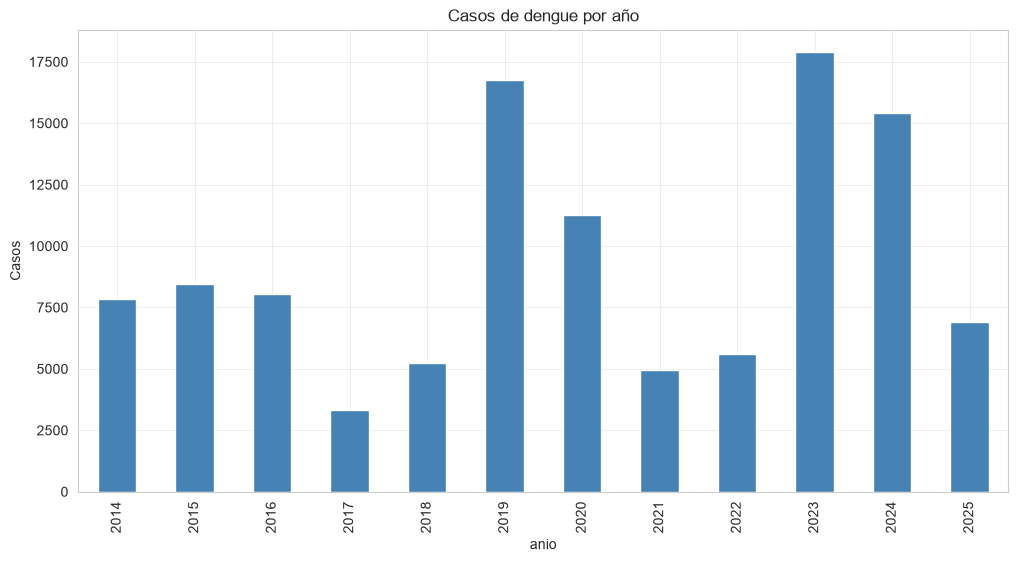

In [13]:
casos_anual = (
    dengue_semanal
    .groupby("anio")["casos_dengue"]
    .sum()
)

casos_anual.plot(
    kind="bar",
    color="steelblue"
)

plt.title(
    "Casos de dengue por año"
)

plt.ylabel(
    "Casos"
)

plt.show()

Este primer gráfico es sobre la cantidad de casos diagnosticados de dengue por año, observamos que 2019, 2023 y 2024 son años "pico" debido a que los casos son considerablemente mayores al resto, a diferencia de 2017 y 2021 que son los que menos casos registrados poseen.

## 6.2 Casos por Semana Epidemiológica

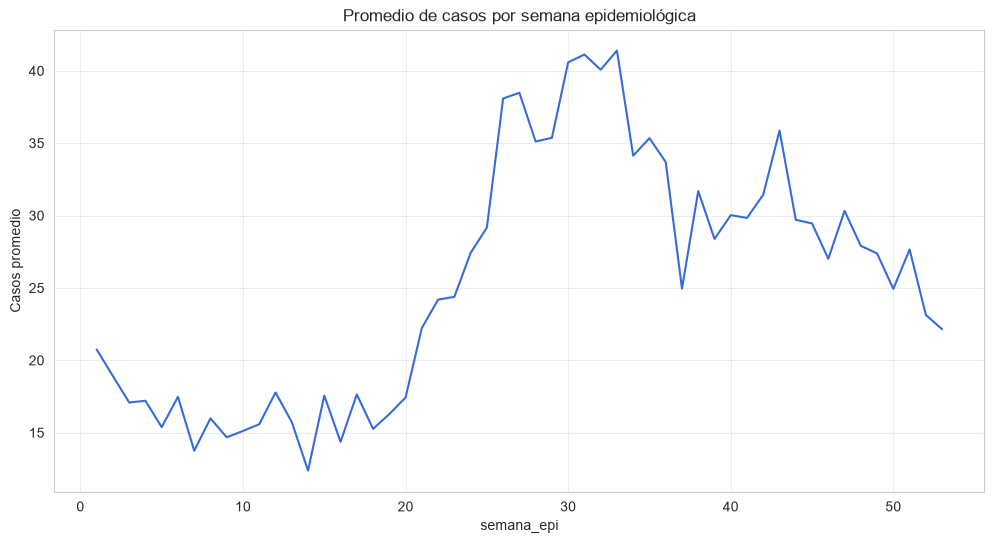

In [14]:
casos_semana = (
    dengue_semanal
    .groupby("semana_epi")["casos_dengue"]
    .mean()
)

casos_semana.plot()

plt.title(
    "Promedio de casos por semana epidemiológica"
)

plt.ylabel(
    "Casos promedio"
)

plt.show()

La "semana epidemiológica" hace referencia a una media que utilizan en los sectores de salud donde dividen el año por periodos exacto de siete días (generalmente de domingo a sábado), esto permite comparar de forma directa el comportamiento de enfermedades semana a semana en diferentes años.

En este caso observamos que en promedio las primeras semanas poseen rangos muy bajos de casos pero a mediados de año dichos casos aumentan de manera signifiativa (llegando a ser inclusive mas del doble)

## 6.3 Series Temporales

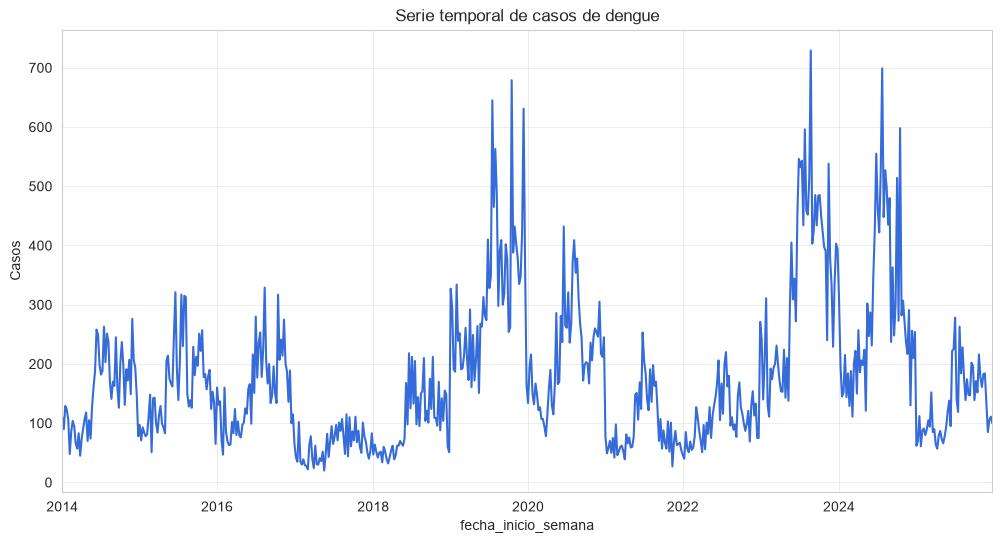

In [16]:
dengue_semanal["fecha_inicio_semana"] = pd.to_datetime(
    dengue_semanal["fecha_inicio_semana"]
)

serie = (
    dengue_semanal
    .groupby("fecha_inicio_semana")["casos_dengue"]
    .sum()
)

serie.plot()

plt.title(
    "Serie temporal de casos de dengue"
)

plt.ylabel(
    "Casos"
)

plt.show()

En este gráfico se nos muestra como los casos se van movilizando a lo largo de los años por medio de las semanas, en este caso observamos como justamente 2019, 2023 y 2024 son los que poseen picos por encima del resto.

## 6.4 Casos por Provincia

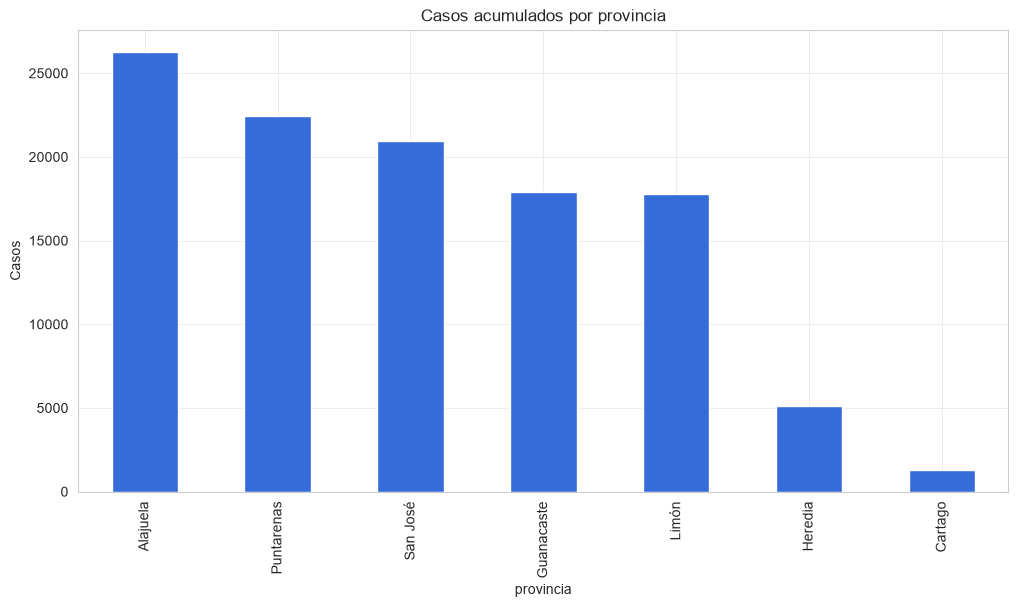

In [17]:
provincia = (
    dengue_semanal
    .groupby("provincia")["casos_dengue"]
    .sum()
    .sort_values(
        ascending=False
    )
)

provincia.plot(
    kind="bar"
)

plt.title(
    "Casos acumulados por provincia"
)

plt.ylabel(
    "Casos"
)

plt.show()

Este gráfico de barras nos muestra la cantidad de casos registrados por provincia mostrando una diferencia abismal entre Alajuela (provincia con mas casos registrados) y Cartago (provincia con menos casos) Cartago al ser una región con un clima de menor temperatura evita que el mosquito del dengue esté con mayor presencia debido a que este habita en regiones cálidad y con alta humedad.

## 6.5 Distribución de Casos

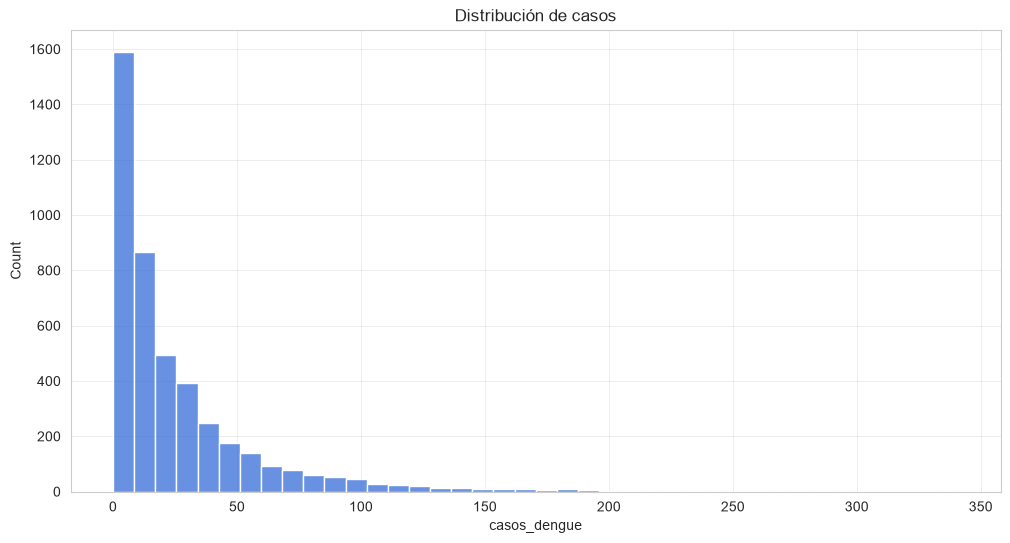

In [18]:
sns.histplot(
    dengue_semanal["casos_dengue"],
    bins=40
)

plt.title(
    "Distribución de casos"
)

plt.show()

Este gráfico nos muestra la cantidad de casos registrados, observamos que regularmente las semanas poseen pocos casos registrados ya que 50 casos registrados a la semana no llega a las 200 ocasiones.

## 6.6 Boxplot Casos

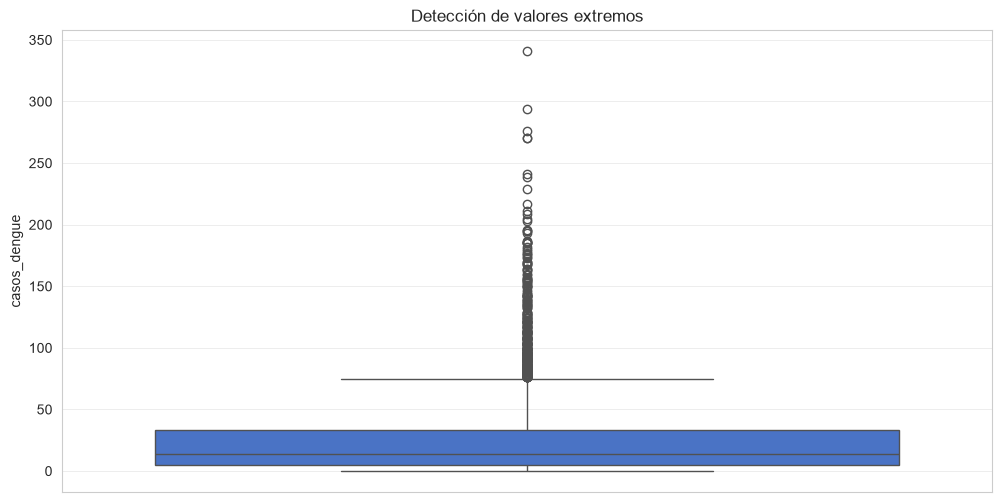

In [19]:
sns.boxplot(
    y=dengue_semanal["casos_dengue"]
)

plt.title(
    "Detección de valores extremos"
)

plt.show()

Como observamos en el gráfico pasado, la mayoría de casos se registran entre 0 50 y siendo que son mas de 0 y menos de 50 donde se registran el 50% de la información, pero además de eso observamos una cantidad alta de outliers (atípicos) siendo que hay un atípico que llegó casi a los 350 registros.

## 6.7 Variables Climáticas

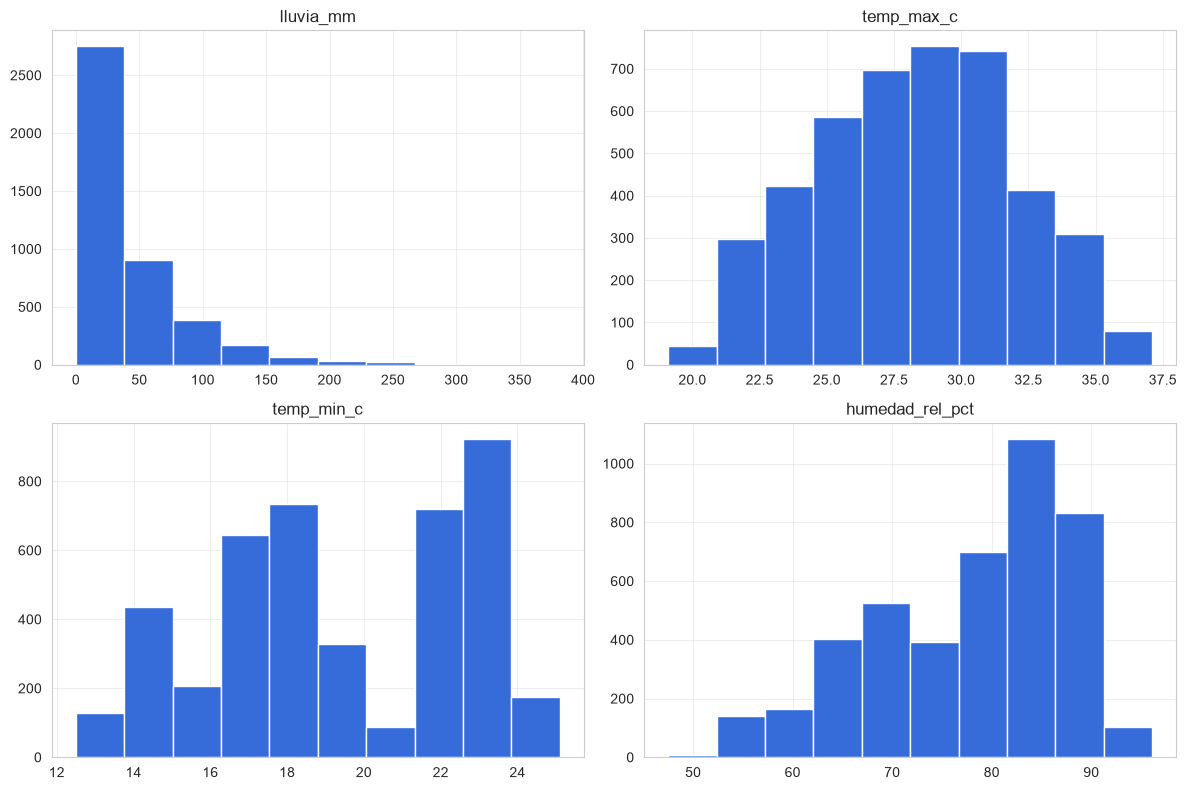

In [20]:
variables_clima = [

    "lluvia_mm",

    "temp_max_c",

    "temp_min_c",

    "humedad_rel_pct"

]

dengue_semanal[
    variables_clima
].hist(
    figsize=(12,8)
)

plt.tight_layout()

plt.show()

En este gráfico mostramos las cuatro variables climáticas que posee el dataset las cuales son:
- lluvia_mm: Que mide la cantidad de lluvia acumulada (en milímetros) y observamos que la mayoría de los periodos poseen muy poca lluvia:
- temp_max_c: La temperatura máxima en grados centígrados, observamos que el máximo fueron 37 grados pero que la mayoría está entre 27.5 y 30 grados.
- temp_min_c: Caso contrario al anterior, este nos da la temperatura máxima, observando que la mas alta es de 24 y el mínimo de 12, pero que la mayoría está entre 22 y 24 y con una cantidad no tan distante entre 16 y 18.
- humedad_rel_pct: La "humedad relativa en porcentaje" mide el porcentaje de humedad en el aire y observamos que la mayoría de datos se sitúan entre el 80 y 90% lo cual es una cantidad enorme de humedad.

## 6.8 Correlaciones

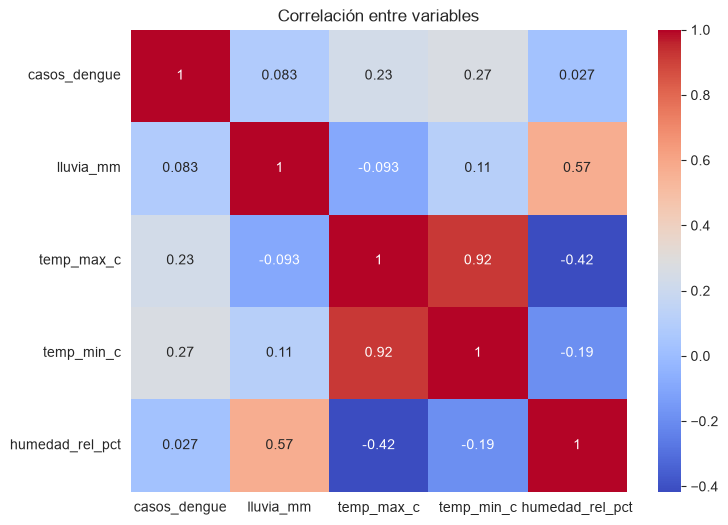

In [21]:
corr = dengue_semanal[
    [
        "casos_dengue",
        "lluvia_mm",
        "temp_max_c",
        "temp_min_c",
        "humedad_rel_pct"
    ]
].corr()

plt.figure(
    figsize=(8,6)
)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title(
    "Correlación entre variables"
)

plt.show()

En este gráfico observamos que las mayorías de variables poseen poca o casi nula relación a excepción de temp_min_c y temp_max_c con un 0.92 lo cual es una relación muy fuerte.

## 6.9 Clima vs Dengue

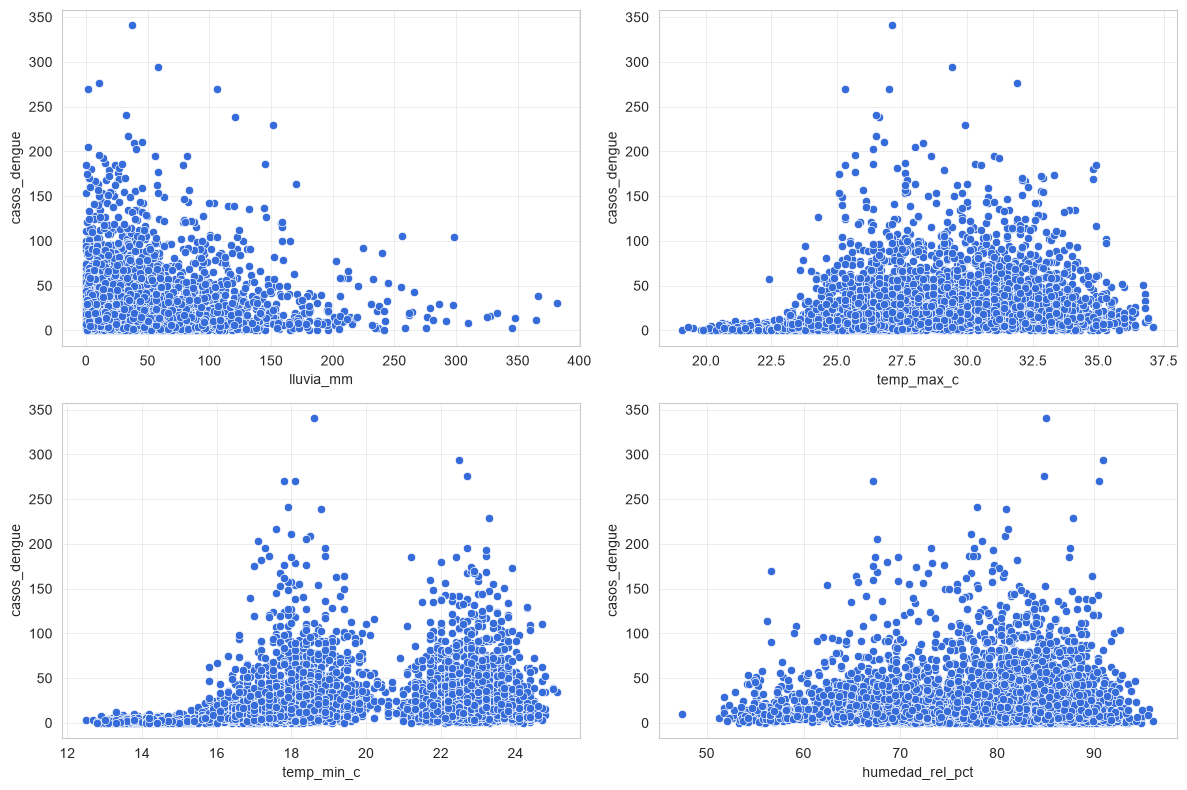

In [22]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(12,8)
)

sns.scatterplot(
    data=dengue_semanal,
    x="lluvia_mm",
    y="casos_dengue",
    ax=axes[0,0]
)

sns.scatterplot(
    data=dengue_semanal,
    x="temp_max_c",
    y="casos_dengue",
    ax=axes[0,1]
)

sns.scatterplot(
    data=dengue_semanal,
    x="temp_min_c",
    y="casos_dengue",
    ax=axes[1,0]
)

sns.scatterplot(
    data=dengue_semanal,
    x="humedad_rel_pct",
    y="casos_dengue",
    ax=axes[1,1]
)

plt.tight_layout()

plt.show()

En este caso observamos como se distribuyen las cuatro variables en relación a la cantidad de dengue registrado, observamos que donde se reportó era un lugar con mucha humedad, una cantidad fuerte de lluvia y un temperatura máxima relativamente alta de casi 27.5 grados

# EDA Modelo 3

Ahora vamos a mostrar algunas observaciones para el tercer modelo

## Distribución de Recomendaciones

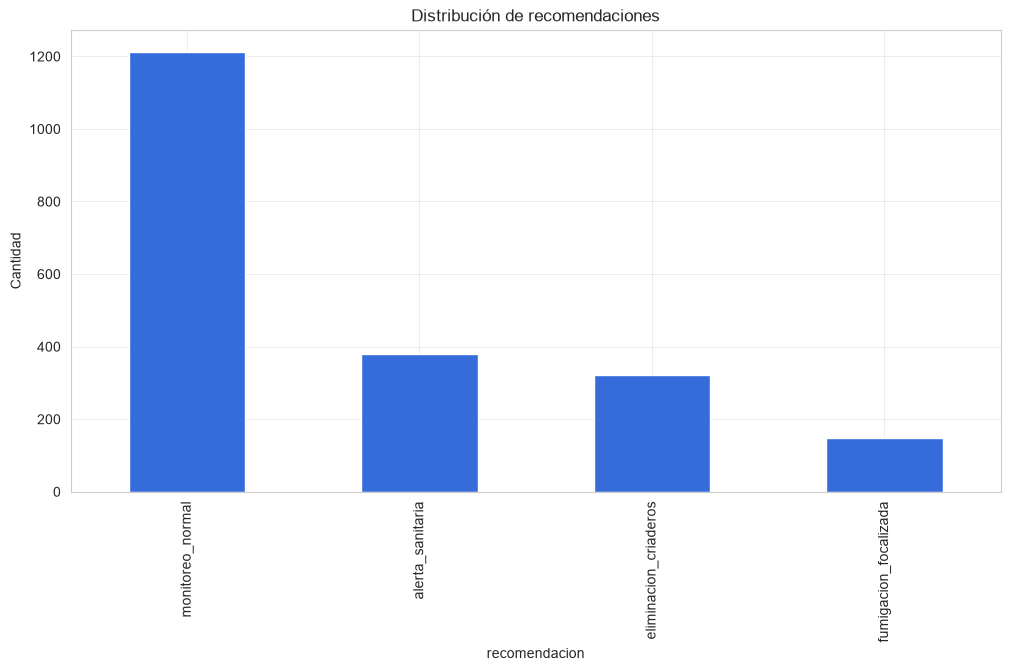

In [23]:
acciones["recomendacion"].value_counts().plot(
    kind="bar"
)

plt.title(
    "Distribución de recomendaciones"
)

plt.ylabel(
    "Cantidad"
)

plt.show()

Observamos que la mayoría de las observaciones solo son "monitoreo_normal" teniendo una cantidad mayor que las otras tres juntas.

## 6.2 Balance de clases

In [24]:
display(
    acciones["recomendacion"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

recomendacion
monitoreo_normal         58.88
alerta_sanitaria         18.40
eliminacion_criaderos    15.58
fumigacion_focalizada     7.14
Name: proportion, dtype: float64

Con casi un 60% observamos que monitoreo_normal es la clase con mayor peso, esto es importante tomarlo en cuenta para el entrenamiento del modelo.

## 6.3 Presencia de Aedes

recomendacion,alerta_sanitaria,eliminacion_criaderos,fumigacion_focalizada,monitoreo_normal
aegypti_detectado,,,,
0,213,185,4,801
1,166,136,143,412


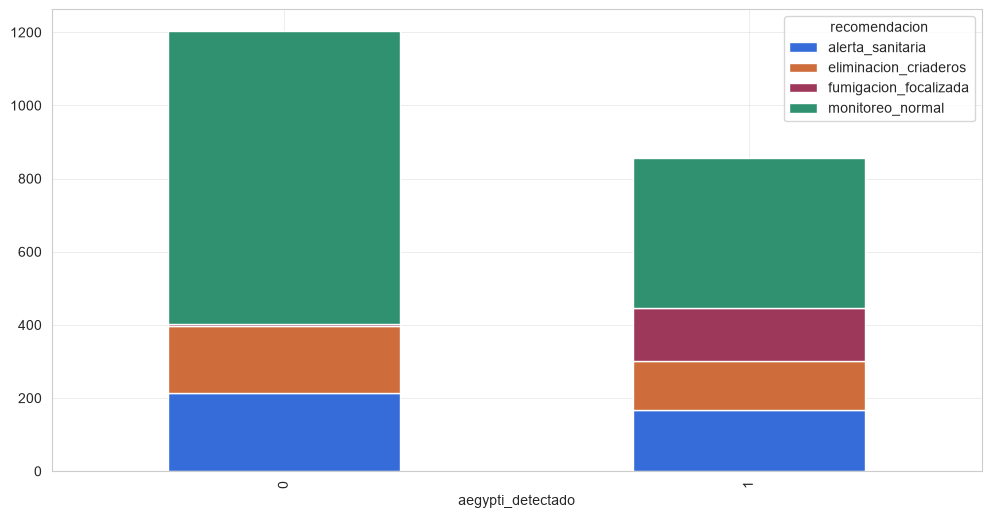

In [27]:
tabla = pd.crosstab(

    acciones["aegypti_detectado"],

    acciones["recomendacion"]

)

display(tabla)

tabla.plot(
    kind="bar",
    stacked=True
)

plt.show()

Observamos como cambian las acciones recomendadas si el aedes aegypti fue detectado o no

## 6.4 Matriz de Correlación

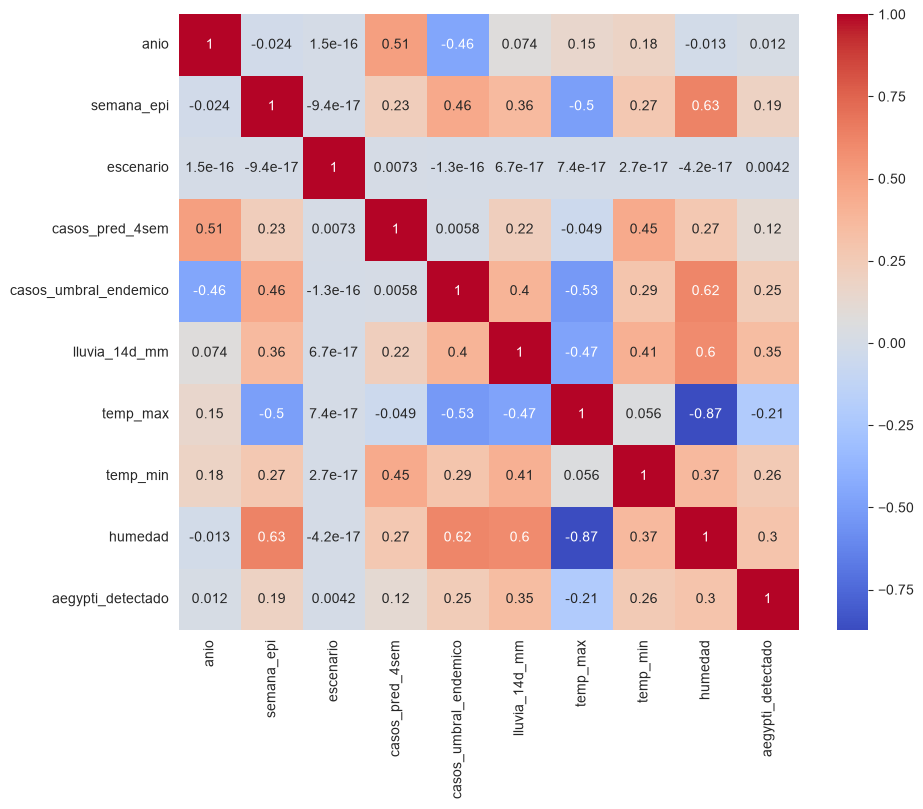

In [28]:
numericas = acciones.select_dtypes(
    include=np.number
)

plt.figure(
    figsize=(10,8)
)

sns.heatmap(
    numericas.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

Observamos que en la matriz de correlación hay pocas correlaciones significativas siendo la mayor "humedad" con "temp_max" con -0.87, es decir una relación fuerte y negativa.